# 03 · Customer Analytics: Retention, RFM Segmentation & Cohorts

**Business questions**
1. How many customers come back, and how quickly?
2. Which customer groups should marketing target, and with what message?
3. How does retention develop month by month for each group of new customers?

Customers are identified by `customer_unique_id` (see notebook 01). Only delivered orders are used.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path('../data/processed')
IMG = Path('../images')
BLUE, RED, GREY, GREEN = '#2E5EAA', '#D1495B', '#9AA5B1', '#2A9D8F'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.float_format', '{:,.2f}'.format)

def save(fig, name):
    fig.savefig(IMG / name, dpi=150, bbox_inches='tight')

orders = pd.read_csv(DATA / 'fact_orders.csv', parse_dates=['order_purchase_timestamp'])
orders['is_late'] = orders['is_late'].astype(float)
delivered = orders[orders['is_delivered']].sort_values('order_purchase_timestamp').copy()
print(f"{len(delivered):,} delivered orders from {delivered['customer_unique_id'].nunique():,} customers")

96,478 delivered orders from 93,358 customers


## 1. Repeat purchases

In [2]:
per_customer = delivered.groupby('customer_unique_id').agg(
    orders=('order_id', 'nunique'), purchase_days=('purchase_date', 'nunique'), revenue=('order_value', 'sum'))

repeaters = per_customer['orders'] > 1
true_repeaters = per_customer['purchase_days'] > 1
print(f"Customers with 2+ orders:               {repeaters.sum():,} ({repeaters.mean():.2%})")
print(f"Customers who returned on a later day:  {true_repeaters.sum():,} ({true_repeaters.mean():.2%})")
print(f"Revenue share from repeat customers:    {per_customer.loc[repeaters, 'revenue'].sum() / per_customer['revenue'].sum():.1%}")
print('\nOrders per customer:'); print(per_customer['orders'].value_counts().sort_index().to_string())

Customers with 2+ orders:               2,801 (3.00%)
Customers who returned on a later day:  2,015 (2.16%)
Revenue share from repeat customers:    5.6%

Orders per customer:
orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1


In [3]:
gaps = (delivered[delivered['customer_unique_id'].isin(per_customer.index[repeaters])]
        .groupby('customer_unique_id')['order_purchase_timestamp']
        .apply(lambda s: (s.iloc[1] - s.iloc[0]).days))
print(f"Repeat customers whose 2nd order was the SAME day: {(gaps == 0).mean():.0%}")
later = gaps[gaps > 0]
print(f"For genuine returns, median days until the 2nd order: {later.median():.0f}")
print(f"Genuine returns that happened within 90 days: {(later <= 90).mean():.0%}")

Repeat customers whose 2nd order was the SAME day: 30%
For genuine returns, median days until the 2nd order: 76
Genuine returns that happened within 90 days: 54%


In [4]:
first_orders = delivered.drop_duplicates('customer_unique_id', keep='first').copy()
first_orders['came_back'] = first_orders['customer_unique_id'].isin(per_customer.index[true_repeaters])
print('Return rate by first-order experience:')
print(first_orders.groupby(first_orders['is_late'].map({0: 'First order on time', 1: 'First order late'}))
      ['came_back'].mean().map('{:.2%}'.format).to_string())

Return rate by first-order experience:
is_late
First order late       1.62%
First order on time    2.20%


**Findings**
- **Only 3.0% of customers placed a second order**, and they contribute just 5.6% of revenue.
- About 30% of those "repeat" customers simply split one shopping trip into two orders on the same day.
  Counting only customers who came back on a later day, **true retention is 2.2%**.
- Repeat customers who genuinely return take a median of **76 days** to place their second order.
- Customers whose first order arrived late were **about 26% less likely to come back** (1.6% vs 2.2%).
  But retention is low even after a good experience, so the bigger issue is that Olist gives customers
  no strong reason to return.

This makes Olist mostly a **one-purchase marketplace**: growth depends almost entirely on acquiring new
customers, which is expensive. Even small gains in retention would be valuable.

## 2. RFM segmentation

**RFM** scores every customer on three things:
- **Recency** – days since their last order (lower is better)
- **Frequency** – number of orders
- **Monetary** – total amount spent

Recency and Monetary are scored 1-5 using quintiles. Frequency **cannot** be split into quintiles here because
97% of customers have exactly one order, so customers are grouped as one-time vs repeat instead.
The snapshot date is the day after the last order in the data.

In [5]:
snapshot = delivered['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)
rfm = delivered.groupby('customer_unique_id').agg(
    last_order=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('order_value', 'sum'))
rfm['recency_days'] = (snapshot - rfm['last_order']).dt.days
rfm['R'] = pd.qcut(rfm['recency_days'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
print(f'Snapshot date: {snapshot.date()}')

score_ranges = pd.DataFrame({
    'R: recency days': rfm.groupby('R')['recency_days'].agg(lambda s: f'{s.min()}-{s.max()}'),
    'M: total spend (R$)': rfm.groupby('M')['monetary'].agg(lambda s: f'{s.min():,.0f}-{s.max():,.0f}')})
score_ranges

Snapshot date: 2018-08-30


,R: recency days,M: total spend (R$)
1,383-713,10-55
2,269-382,55-87
3,178-268,87-133
4,93-177,133-209
5,0-92,"209-13,664"


In [6]:
def segment(row):
    if row['frequency'] >= 2:
        return 'Champions' if row['R'] >= 4 else 'At-Risk Repeat Buyers'
    if row['R'] >= 4:
        return 'Promising (New, High Value)' if row['M'] >= 4 else 'New Customers'
    if row['R'] == 3:
        return 'Need Attention'
    return 'Lost High-Value' if row['M'] >= 4 else 'Lost / Hibernating'

rfm['segment'] = rfm.apply(segment, axis=1)

segments = (rfm.groupby('segment')
            .agg(customers=('frequency', 'size'), revenue=('monetary', 'sum'),
                 avg_spend=('monetary', 'mean'), avg_recency_days=('recency_days', 'mean'),
                 avg_orders=('frequency', 'mean'))
            .sort_values('revenue', ascending=False))
segments['customer_share'] = segments['customers'] / segments['customers'].sum() * 100
segments['revenue_share'] = segments['revenue'] / segments['revenue'].sum() * 100
segments

,customers,revenue,avg_spend,avg_recency_days,avg_orders,customer_share,revenue_share
segment,,,,,,,
"Promising (New, High Value)",14509,"4,382,610.68",302.06,91.47,1.00,15.54,28.42
Lost High-Value,13668,"4,210,984.74",308.09,394.33,1.00,14.64,27.31
Need Attention,18118,"2,739,487.48",151.20,220.63,1.00,19.41,17.77
Lost / Hibernating,22426,"1,630,429.12",72.70,395.99,1.00,24.02,10.57
New Customers,21836,"1,592,074.27",72.91,89.77,1.00,23.39,10.32
At-Risk Repeat Buyers,1587,"473,301.19",298.24,319.85,2.08,1.70,3.07
Champions,1214,"390,886.27",321.98,89.03,2.15,1.30,2.53


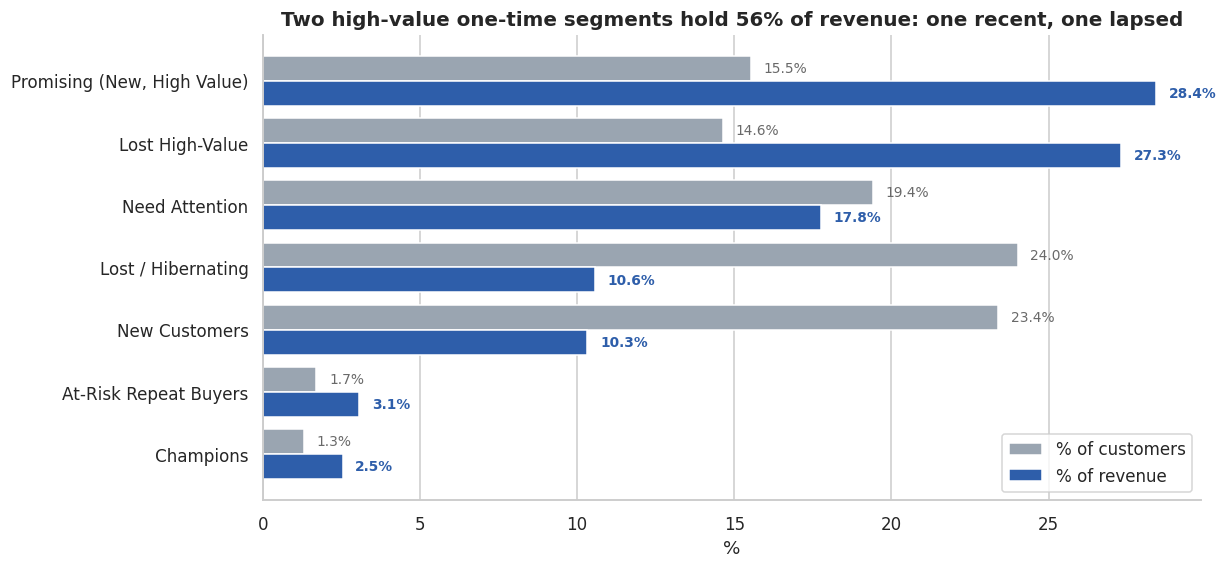

In [7]:
seg_plot = segments.sort_values('revenue_share')
fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(seg_plot))
ax.barh(y + 0.2, seg_plot['customer_share'], height=0.4, color=GREY, label='% of customers')
ax.barh(y - 0.2, seg_plot['revenue_share'], height=0.4, color=BLUE, label='% of revenue')
ax.set_yticks(y); ax.set_yticklabels(seg_plot.index)
for i, (c, r) in enumerate(zip(seg_plot['customer_share'], seg_plot['revenue_share'])):
    ax.text(r + 0.4, i - 0.2, f'{r:.1f}%', va='center', fontsize=9, color=BLUE, fontweight='bold')
    ax.text(c + 0.4, i + 0.2, f'{c:.1f}%', va='center', fontsize=9, color='dimgray')
ax.set_xlabel('%'); ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
ax.set_title('Two high-value one-time segments hold 56% of revenue: one recent, one lapsed')
save(fig, '08_rfm_segments.png'); plt.show()

**Segment playbook**

| Segment | Who they are | Recommended action |
|---|---|---|
| **Promising (New, High Value)** | 15.5% of customers, 28.4% of revenue; one recent order averaging R$302 | Highest-priority target: personalised second-purchase offer within ~30-60 days |
| **Lost High-Value** | 14.6% of customers, 27.3% of revenue; spent R$308 but last order >9 months ago | Win-back campaign with a strong incentive; survey why they left |
| **Need Attention** | 19.4% of customers; last order 6-9 months ago | Re-engagement emails before they become "lost" |
| **New Customers** | 23.4% of customers; recent, low spend (avg R$73) | Cross-sell to raise basket size; free-shipping thresholds |
| **Champions** | 1.3% of customers; repeat and recent | Loyalty rewards, early access, referral programme |
| **At-Risk Repeat Buyers** | 1.7% of customers; bought 2+ times but not recently | Personal "we miss you" offer; they already trust the platform |
| **Lost / Hibernating** | 24.0% of customers; low spend, long gone | Low-cost channels only (no expensive incentives) |

## 3. Cohort retention

Customers are grouped by the month of their **first** purchase (their cohort). For each later month, we measure the
share of that cohort who placed another order. Cohorts from Jan 2017 to Aug 2018 are included.

In [8]:
delivered['cohort'] = delivered.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
delivered['order_period'] = delivered['order_purchase_timestamp'].dt.to_period('M')
delivered['months_since_first'] = (delivered['order_period'] - delivered['cohort']).apply(lambda x: x.n)

window = delivered[(delivered['cohort'] >= pd.Period('2017-01', 'M')) & (delivered['cohort'] <= pd.Period('2018-08', 'M'))]
cohort_counts = window.pivot_table(index='cohort', columns='months_since_first',
                                   values='customer_unique_id', aggfunc='nunique')
# A missing cell means nobody returned (0), unless that month is after the end of the data
last_period = pd.Period('2018-08', 'M')
for cohort in cohort_counts.index:
    observable = [m for m in cohort_counts.columns if cohort + m <= last_period]
    cohort_counts.loc[cohort, observable] = cohort_counts.loc[cohort, observable].fillna(0)

cohort_size = cohort_counts[0]
retention = cohort_counts.divide(cohort_size, axis=0) * 100
retention.index = retention.index.astype(str)
retention.iloc[:, :7].round(2)

months_since_first,0,1,2,3,4,5,6
cohort,,,,,,,
2017-01,100.00,0.28,0.28,0.14,0.42,0.14,0.42
2017-02,100.00,0.18,0.31,0.12,0.43,0.12,0.25
2017-03,100.00,0.44,0.36,0.40,0.36,0.16,0.16
2017-04,100.00,0.62,0.22,0.18,0.27,0.27,0.35
2017-05,100.00,0.46,0.46,0.29,0.29,0.32,0.41
2017-06,100.00,0.49,0.40,0.43,0.30,0.40,0.36
2017-07,100.00,0.53,0.35,0.24,0.29,0.21,0.32
2017-08,100.00,0.69,0.35,0.27,0.35,0.52,0.30
2017-09,100.00,0.70,0.55,0.27,0.45,0.22,0.22


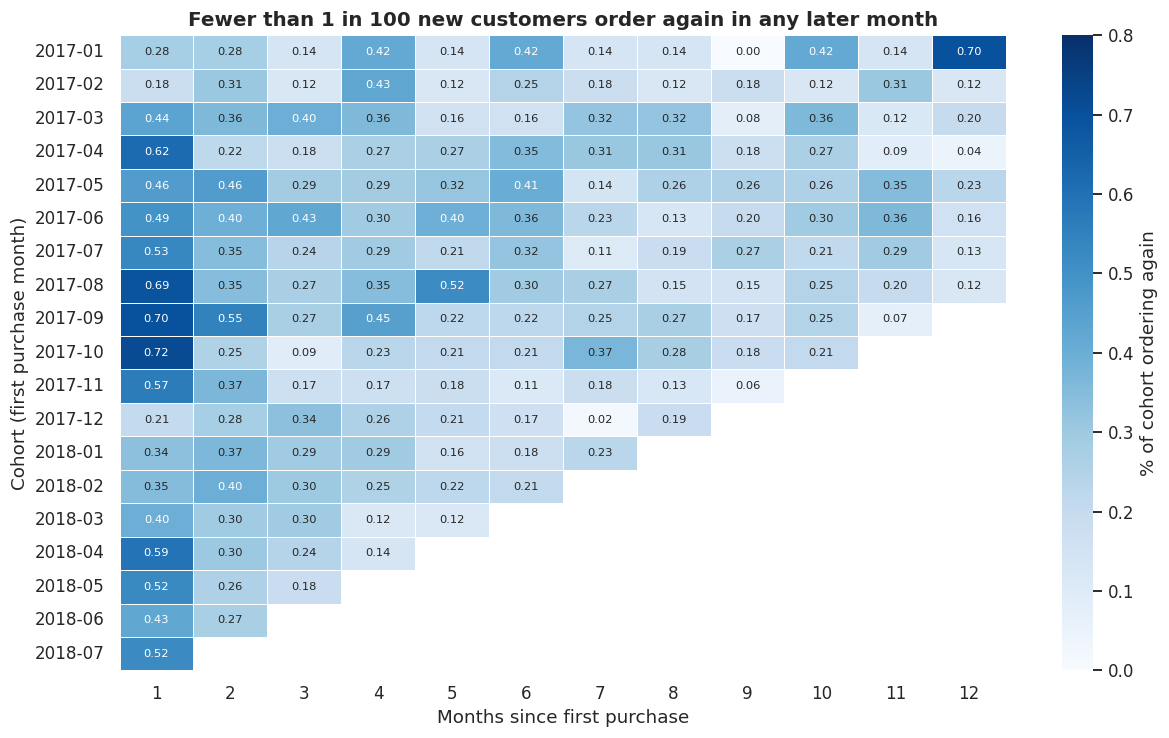

In [9]:
heat = retention.loc[:'2018-07', 1:12]
fig, ax = plt.subplots(figsize=(13, 7.5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=0.8, linewidths=0.5,
            cbar_kws={'label': '% of cohort ordering again'}, ax=ax, annot_kws={'size': 7.5})
ax.grid(False)
ax.set_title('Fewer than 1 in 100 new customers order again in any later month')
ax.set_xlabel('Months since first purchase'); ax.set_ylabel('Cohort (first purchase month)')
save(fig, '09_cohort_retention_heatmap.png'); plt.show()

In [10]:
print(f"Average month-1 retention: {retention[1].mean():.2f}%")
print(f"Largest cohort: {cohort_size.idxmax()} with {int(cohort_size.max()):,} new customers")
print(f"Average new customers per month (2018): {cohort_size.loc['2018-01':'2018-08'].mean():,.0f}")

Average month-1 retention: 0.48%
Largest cohort: 2017-11 with 7,060 new customers
Average new customers per month (2018): 6,370


**Findings**
- On average only **0.48% of new customers order again in their second month**, and later months are similar or lower.
- No cohort ever retains more than 1% in any month, including the large Black Friday cohort (Nov 2017).
- With ~6,400 new customers a month in 2018 and almost no retention, revenue growth stalled once acquisition
  stopped growing, which explains the 2018 plateau seen in notebook 02.

## 4. Export segments for the dashboard

In [11]:
rfm_out = rfm.reset_index()[['customer_unique_id', 'recency_days', 'frequency', 'monetary', 'R', 'M', 'segment']]
rfm_out.to_csv(DATA / 'customer_segments.csv', index=False)
print(f'Saved {len(rfm_out):,} customers to data/processed/customer_segments.csv')

Saved 93,358 customers to data/processed/customer_segments.csv
